# 01 — Análise Exploratória (EDA)
## Genna Content Machine

Dataset: 140 posts do @genna.brasil (116 Reels + 24 Carrosséis)  
Período: Dez 2025 → Mar 2026  
Features: 62 features extraídas por IA + 19 métricas de performance

In [ ]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

PROJECT_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["figure.dpi"] = 100

df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "general_dataset.parquet")
reels = df[df["post_type"] == "REEL"].copy()
carousels = df[df["post_type"] == "FEED_CAROUSEL"].copy()

print(f"Dataset: {df.shape[0]} posts × {df.shape[1]} colunas")
print(f"  Reels: {len(reels)}  |  Carrosséis: {len(carousels)}")
print(f"  Período: {df['date_br'].min().strftime('%Y-%m-%d')} → {df['date_br'].max().strftime('%Y-%m-%d')}")

Dataset: 140 posts × 92 colunas
  Reels: 116  |  Carrosséis: 24
  Período: 2025-12-28 → 2026-03-24


## 1. Distribuição das Métricas de Performance

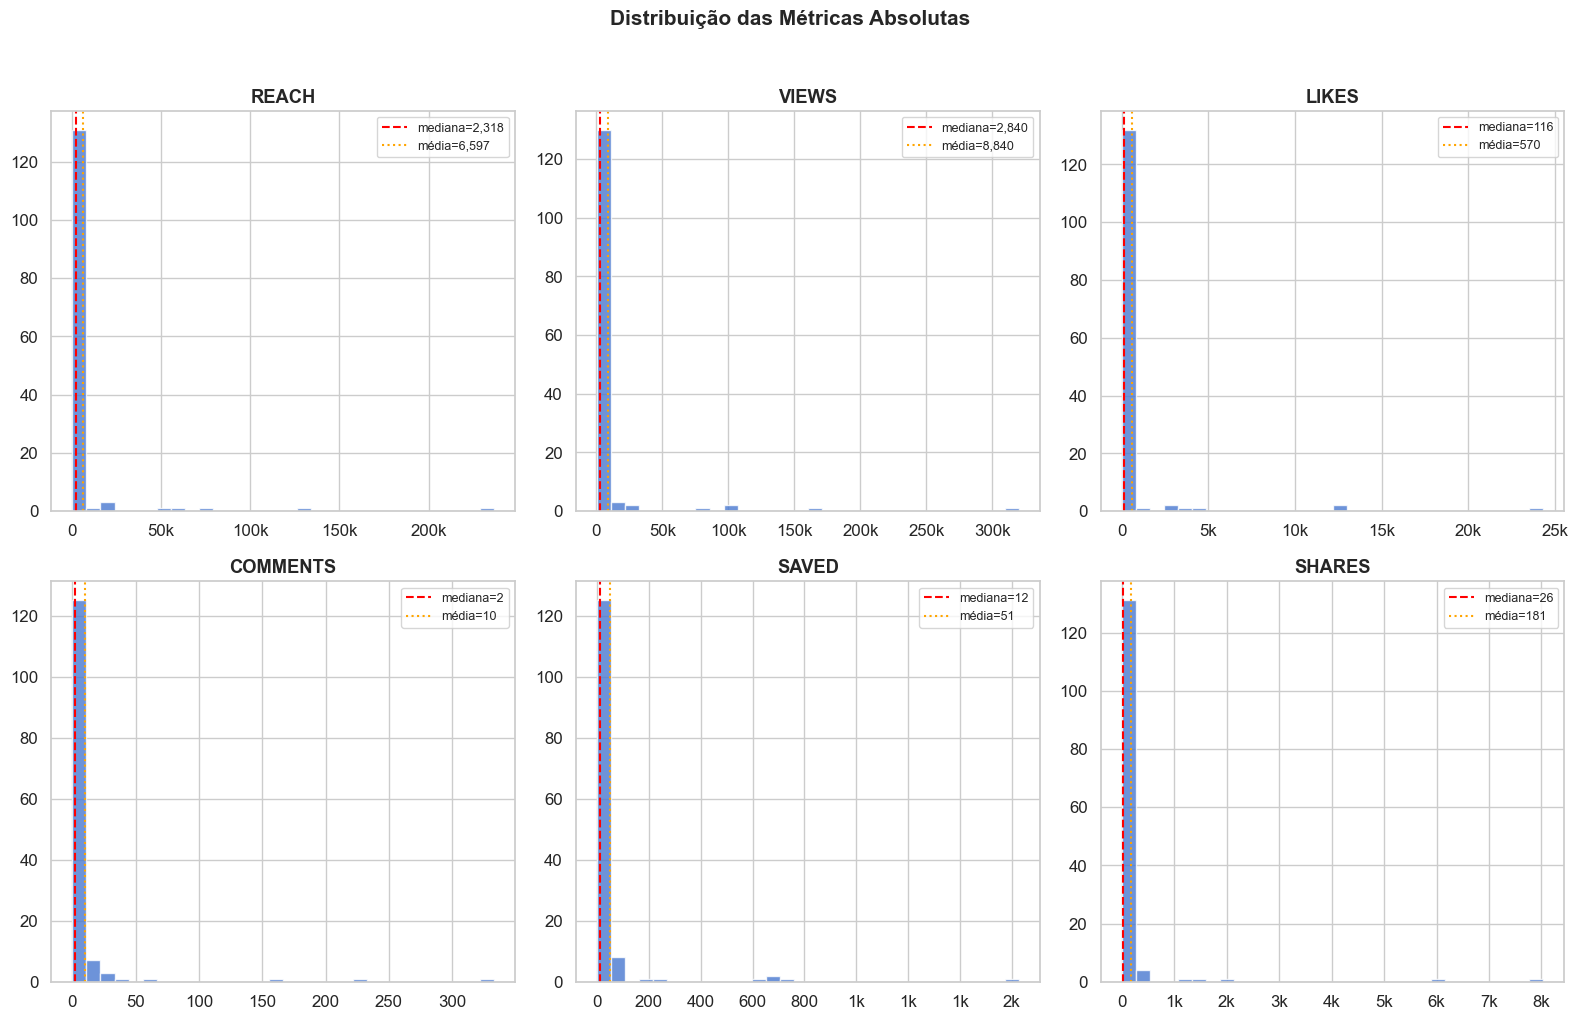


Estatísticas descritivas:


,reach,views,likes,comments,saved,shares
count,140.0,140.0,140.0,140.0,140.0,140.0
mean,6597.0,8840.0,570.0,10.0,51.0,181.0
std,24369.0,32858.0,2569.0,37.0,176.0,871.0
min,455.0,561.0,10.0,0.0,0.0,0.0
25%,1348.0,2015.0,43.0,0.0,6.0,7.0
50%,2318.0,2840.0,116.0,2.0,12.0,26.0
75%,2990.0,3662.0,189.0,6.0,27.0,70.0
max,236477.0,319890.0,24328.0,333.0,1626.0,8035.0


In [2]:
metrics = ["reach", "views", "likes", "comments", "saved", "shares"]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, col in zip(axes.flat, metrics):
    data = df[col].dropna()
    ax.hist(data, bins=30, edgecolor="white", alpha=0.8)
    ax.axvline(data.median(), color="red", ls="--", lw=1.5, label=f"mediana={data.median():,.0f}")
    ax.axvline(data.mean(), color="orange", ls=":", lw=1.5, label=f"média={data.mean():,.0f}")
    ax.set_title(col.upper(), fontweight="bold")
    ax.legend(fontsize=9)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}k" if x >= 1000 else f"{x:.0f}"))

fig.suptitle("Distribuição das Métricas Absolutas", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print("\nEstatísticas descritivas:")
df[metrics].describe().round(0)

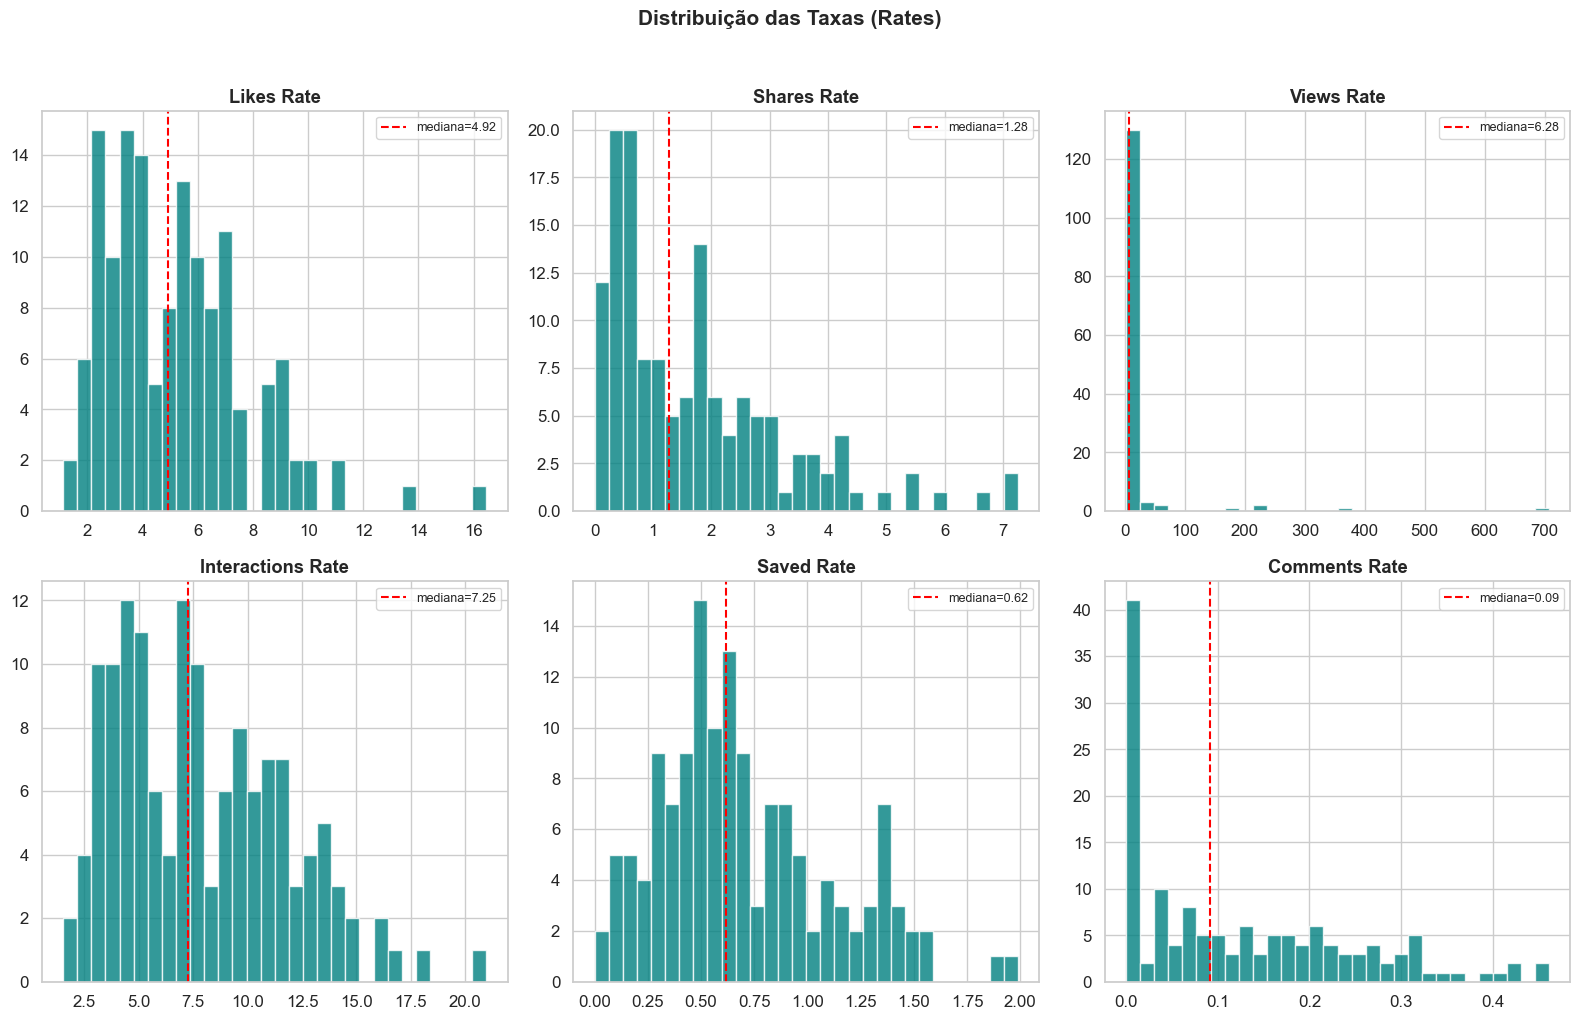

In [3]:
rate_metrics = ["likes_rate", "shares_rate", "views_rate", "interactions_rate", "saved_rate", "comments_rate"]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, col in zip(axes.flat, rate_metrics):
    data = df[col].dropna()
    ax.hist(data, bins=30, edgecolor="white", alpha=0.8, color="teal")
    ax.axvline(data.median(), color="red", ls="--", lw=1.5, label=f"mediana={data.median():.2f}")
    ax.set_title(col.replace("_", " ").title(), fontweight="bold")
    ax.legend(fontsize=9)

fig.suptitle("Distribuição das Taxas (Rates)", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 2. Performance ao Longo do Tempo

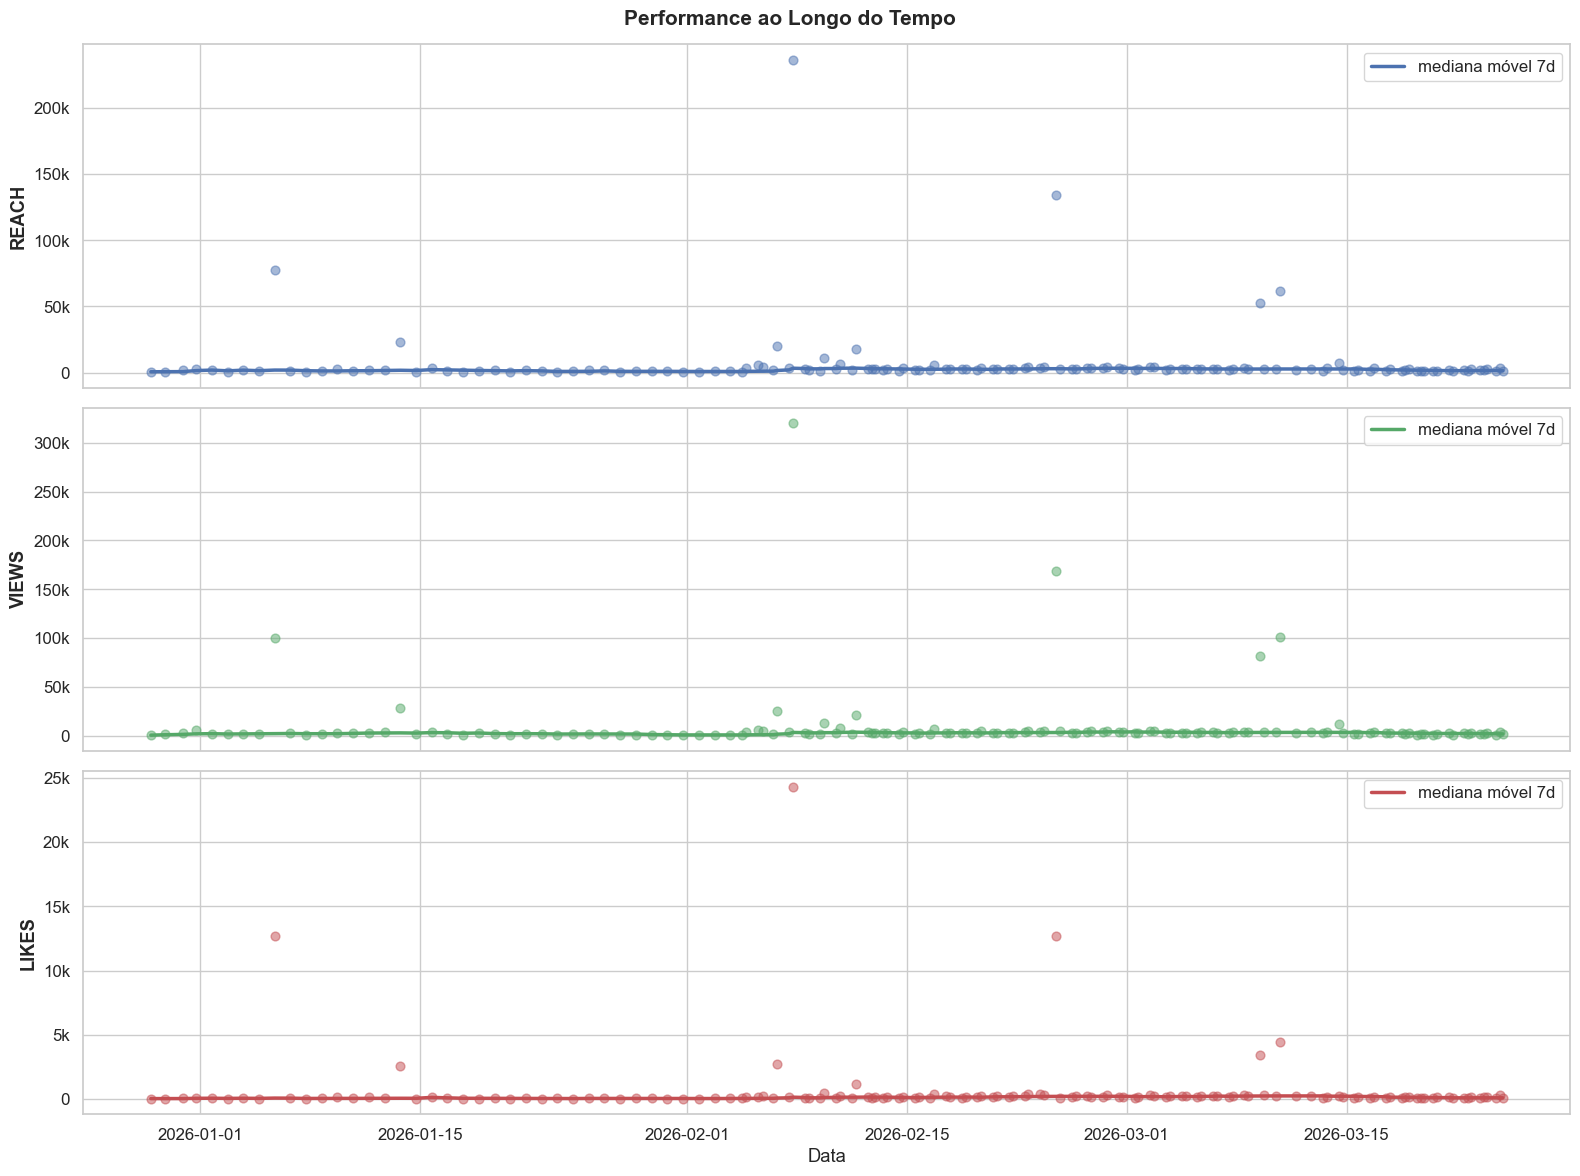

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

for ax, col, color in zip(axes, ["reach", "views", "likes"], ["#4C72B0", "#55A868", "#C44E52"]):
    ax.scatter(df["date_br"], df[col], c=color, alpha=0.5, s=40)
    rolling = df.set_index("date_br")[col].rolling("7D").median()
    ax.plot(rolling.index, rolling.values, color=color, lw=2.5, label="mediana móvel 7d")
    ax.set_ylabel(col.upper(), fontweight="bold")
    ax.legend()
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}k" if x >= 1000 else f"{x:.0f}"))

axes[-1].set_xlabel("Data")
fig.suptitle("Performance ao Longo do Tempo", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

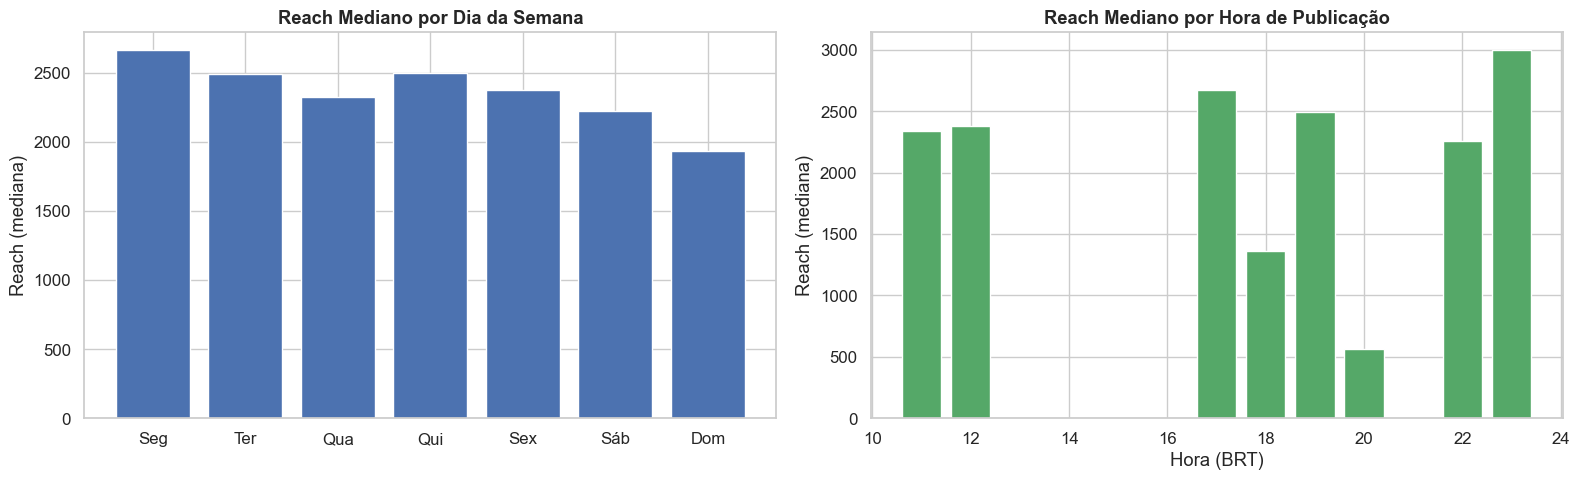

In [5]:
df["week"] = df["date_br"].dt.isocalendar().week.astype(int)
df["month"] = df["date_br"].dt.to_period("M").astype(str)
df["weekday"] = df["date_br"].dt.day_name()
df["hour"] = df["date_br"].dt.hour

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
week_agg = df.groupby("weekday")["reach"].median().reindex(weekday_order)
axes[0].bar(range(7), week_agg.values, color="#4C72B0", edgecolor="white")
axes[0].set_xticks(range(7))
axes[0].set_xticklabels(["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"])
axes[0].set_title("Reach Mediano por Dia da Semana", fontweight="bold")
axes[0].set_ylabel("Reach (mediana)")

hour_agg = df.groupby("hour")["reach"].median()
axes[1].bar(hour_agg.index, hour_agg.values, color="#55A868", edgecolor="white")
axes[1].set_title("Reach Mediano por Hora de Publicação", fontweight="bold")
axes[1].set_xlabel("Hora (BRT)")
axes[1].set_ylabel("Reach (mediana)")

plt.tight_layout()
plt.show()

## 3. Reels vs Carrosséis

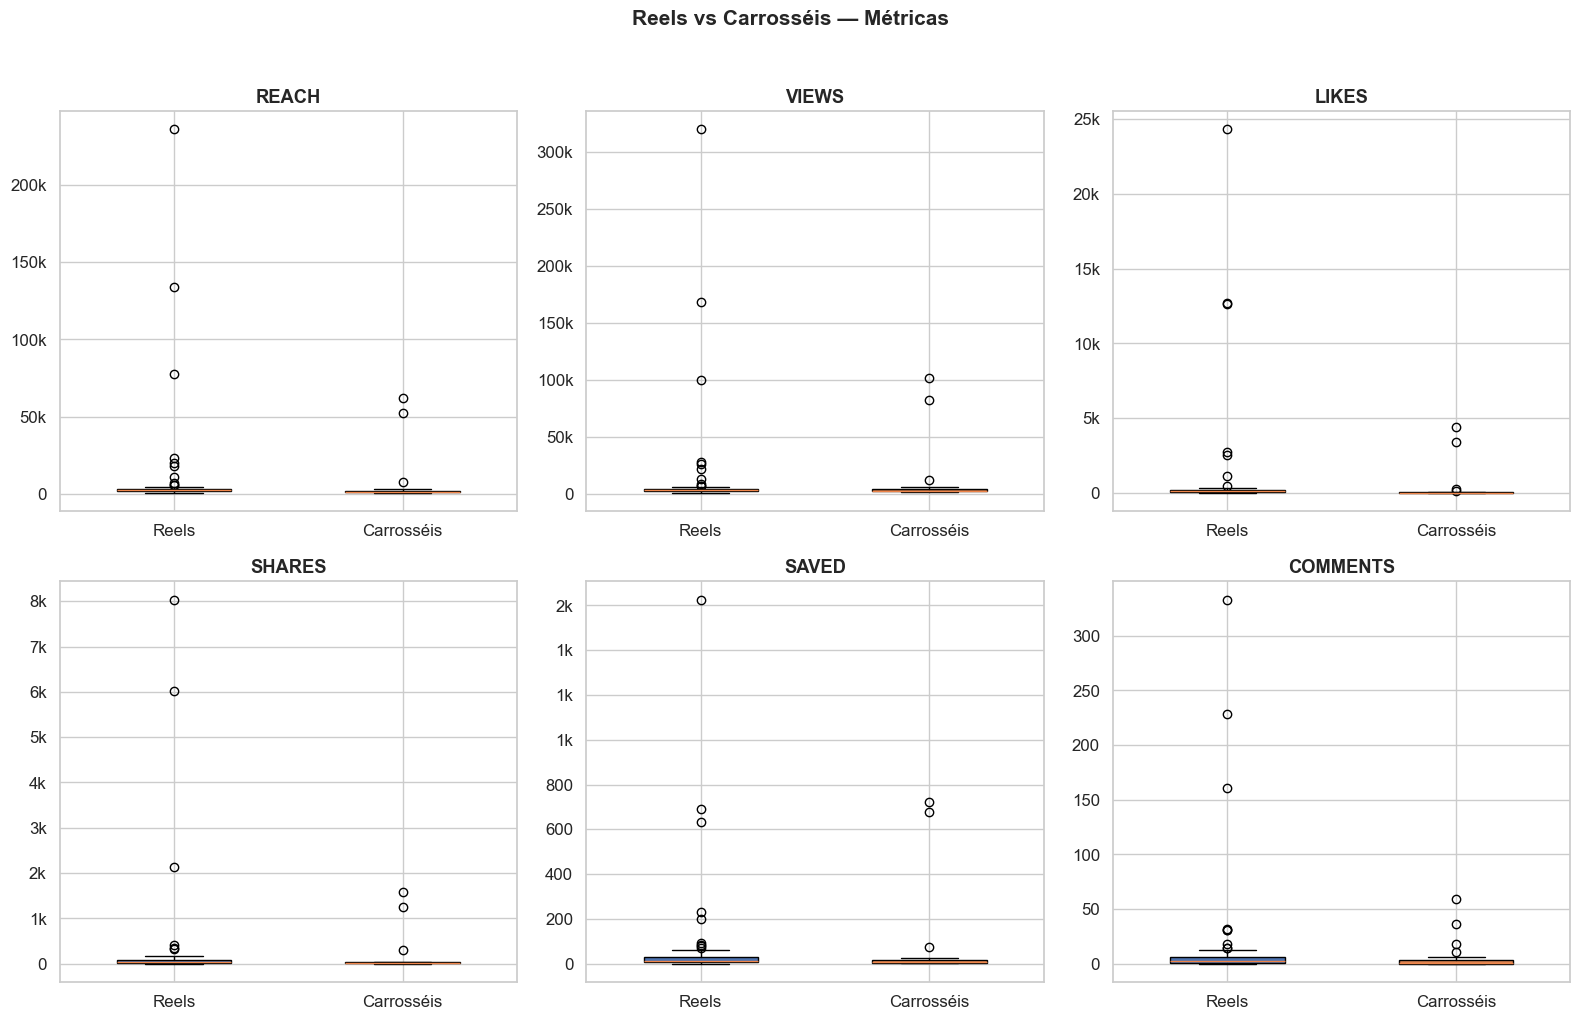

Medianas:
  reach            Reels=   2,368  Carrosséis=   1,323  (Reels 1.8x)
  views            Reels=   2,924  Carrosséis=   2,576  (Reels 1.1x)
  likes            Reels=     128  Carrosséis=      34  (Reels 3.8x)
  shares           Reels=      36  Carrosséis=       8  (Reels 4.8x)
  saved            Reels=      14  Carrosséis=       6  (Reels 2.2x)
  comments         Reels=       2  Carrosséis=       0  (Reels 4.0x)


In [6]:
compare_metrics = ["reach", "views", "likes", "shares", "saved", "comments"]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, col in zip(axes.flat, compare_metrics):
    data = [reels[col].dropna(), carousels[col].dropna()]
    bp = ax.boxplot(data, labels=["Reels", "Carrosséis"], patch_artist=True, widths=0.5)
    bp["boxes"][0].set_facecolor("#4C72B0")
    bp["boxes"][1].set_facecolor("#DD8452")
    ax.set_title(col.upper(), fontweight="bold")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}k" if x >= 1000 else f"{x:.0f}"))

fig.suptitle("Reels vs Carrosséis — Métricas", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print("Medianas:")
for col in compare_metrics:
    r_med = reels[col].median()
    c_med = carousels[col].median()
    ratio = r_med / c_med if c_med > 0 else float("inf")
    print(f"  {col:15s}  Reels={r_med:>8,.0f}  Carrosséis={c_med:>8,.0f}  (Reels {ratio:.1f}x)")

## 4. Distribuição das Features Numéricas

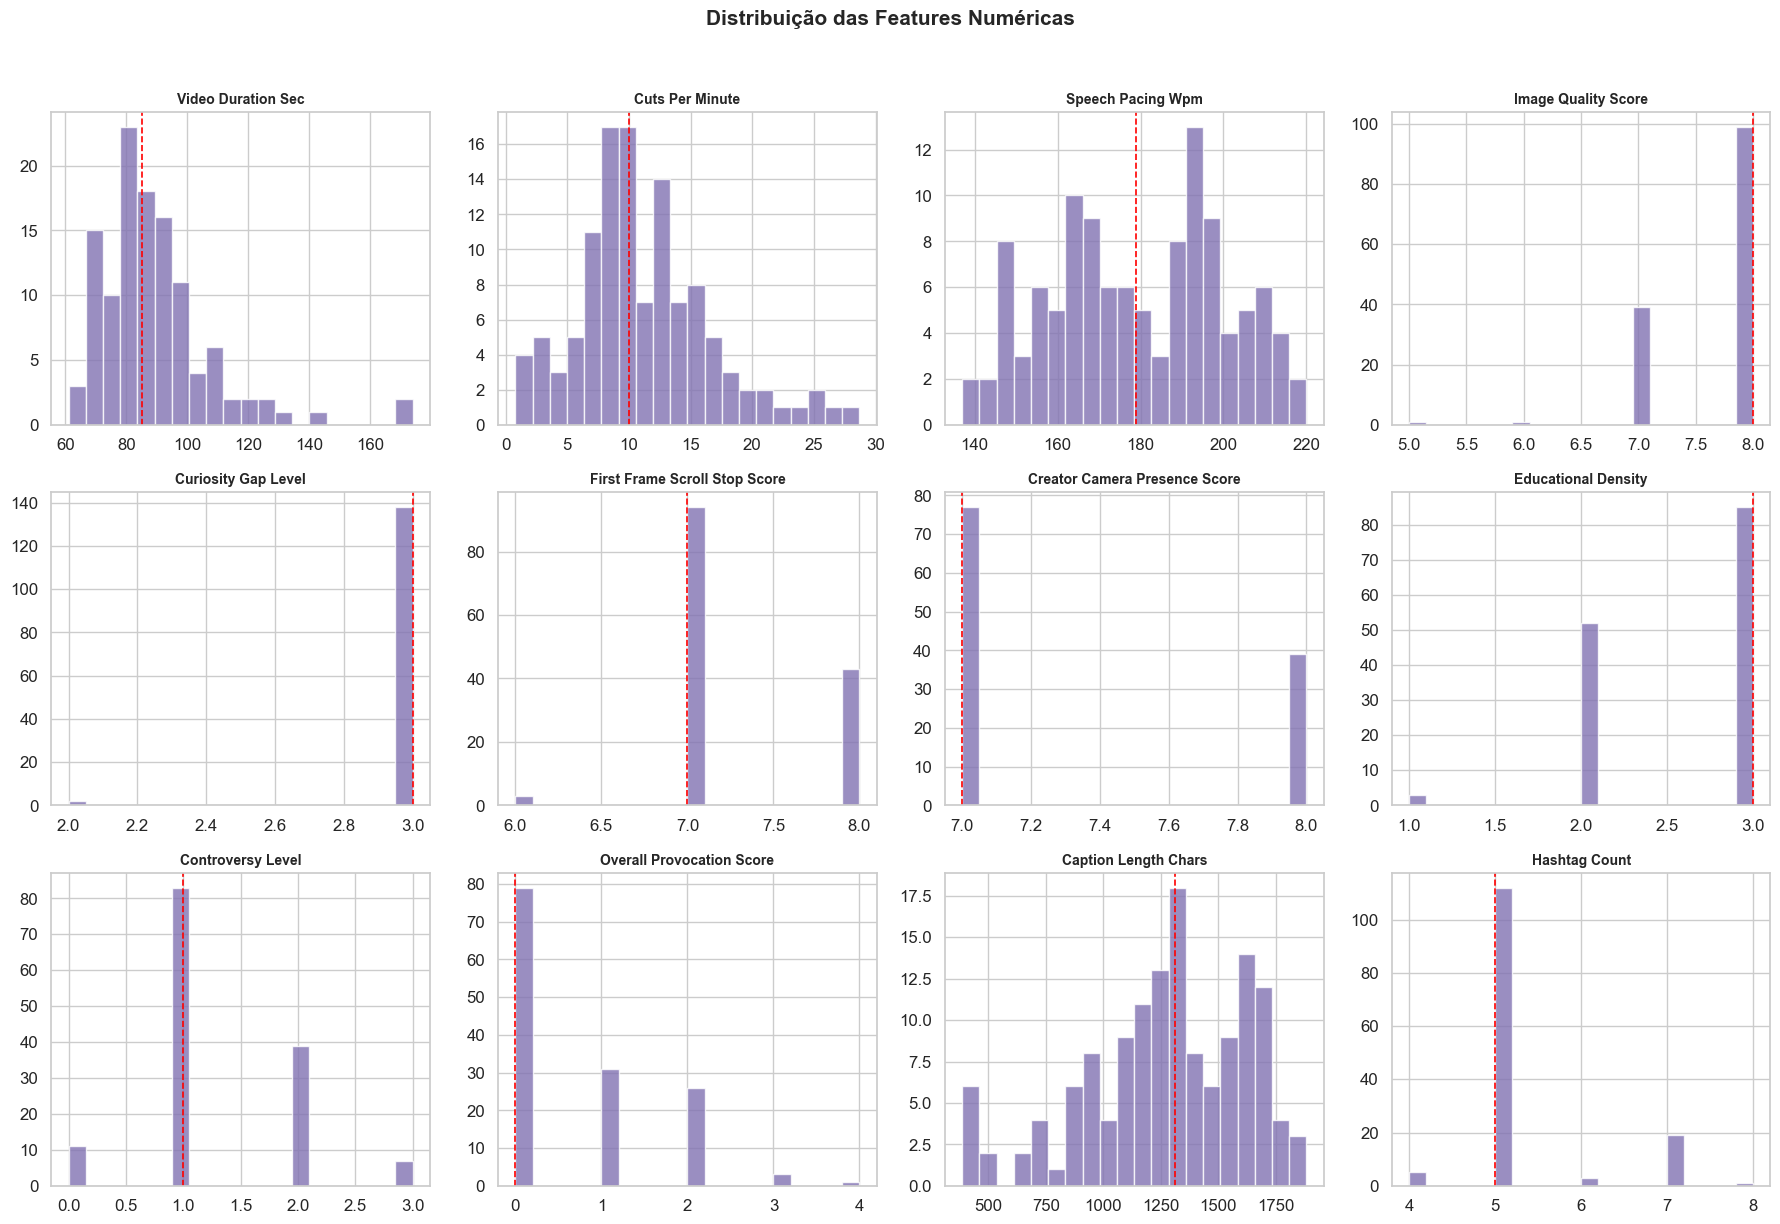

In [7]:
num_features = [
    "video_duration_sec", "cuts_per_minute", "speech_pacing_wpm",
    "image_quality_score", "curiosity_gap_level", "first_frame_scroll_stop_score",
    "creator_camera_presence_score", "educational_density",
    "controversy_level", "overall_provocation_score",
    "caption_length_chars", "hashtag_count",
]

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
for ax, feat in zip(axes.flat, num_features):
    data = df[feat].dropna()
    ax.hist(data, bins=20, edgecolor="white", alpha=0.8, color="#8172B2")
    ax.set_title(feat.replace("_", " ").title(), fontsize=10, fontweight="bold")
    ax.axvline(data.median(), color="red", ls="--", lw=1.2)

fig.suptitle("Distribuição das Features Numéricas", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 5. Distribuição das Features Categóricas (top features)

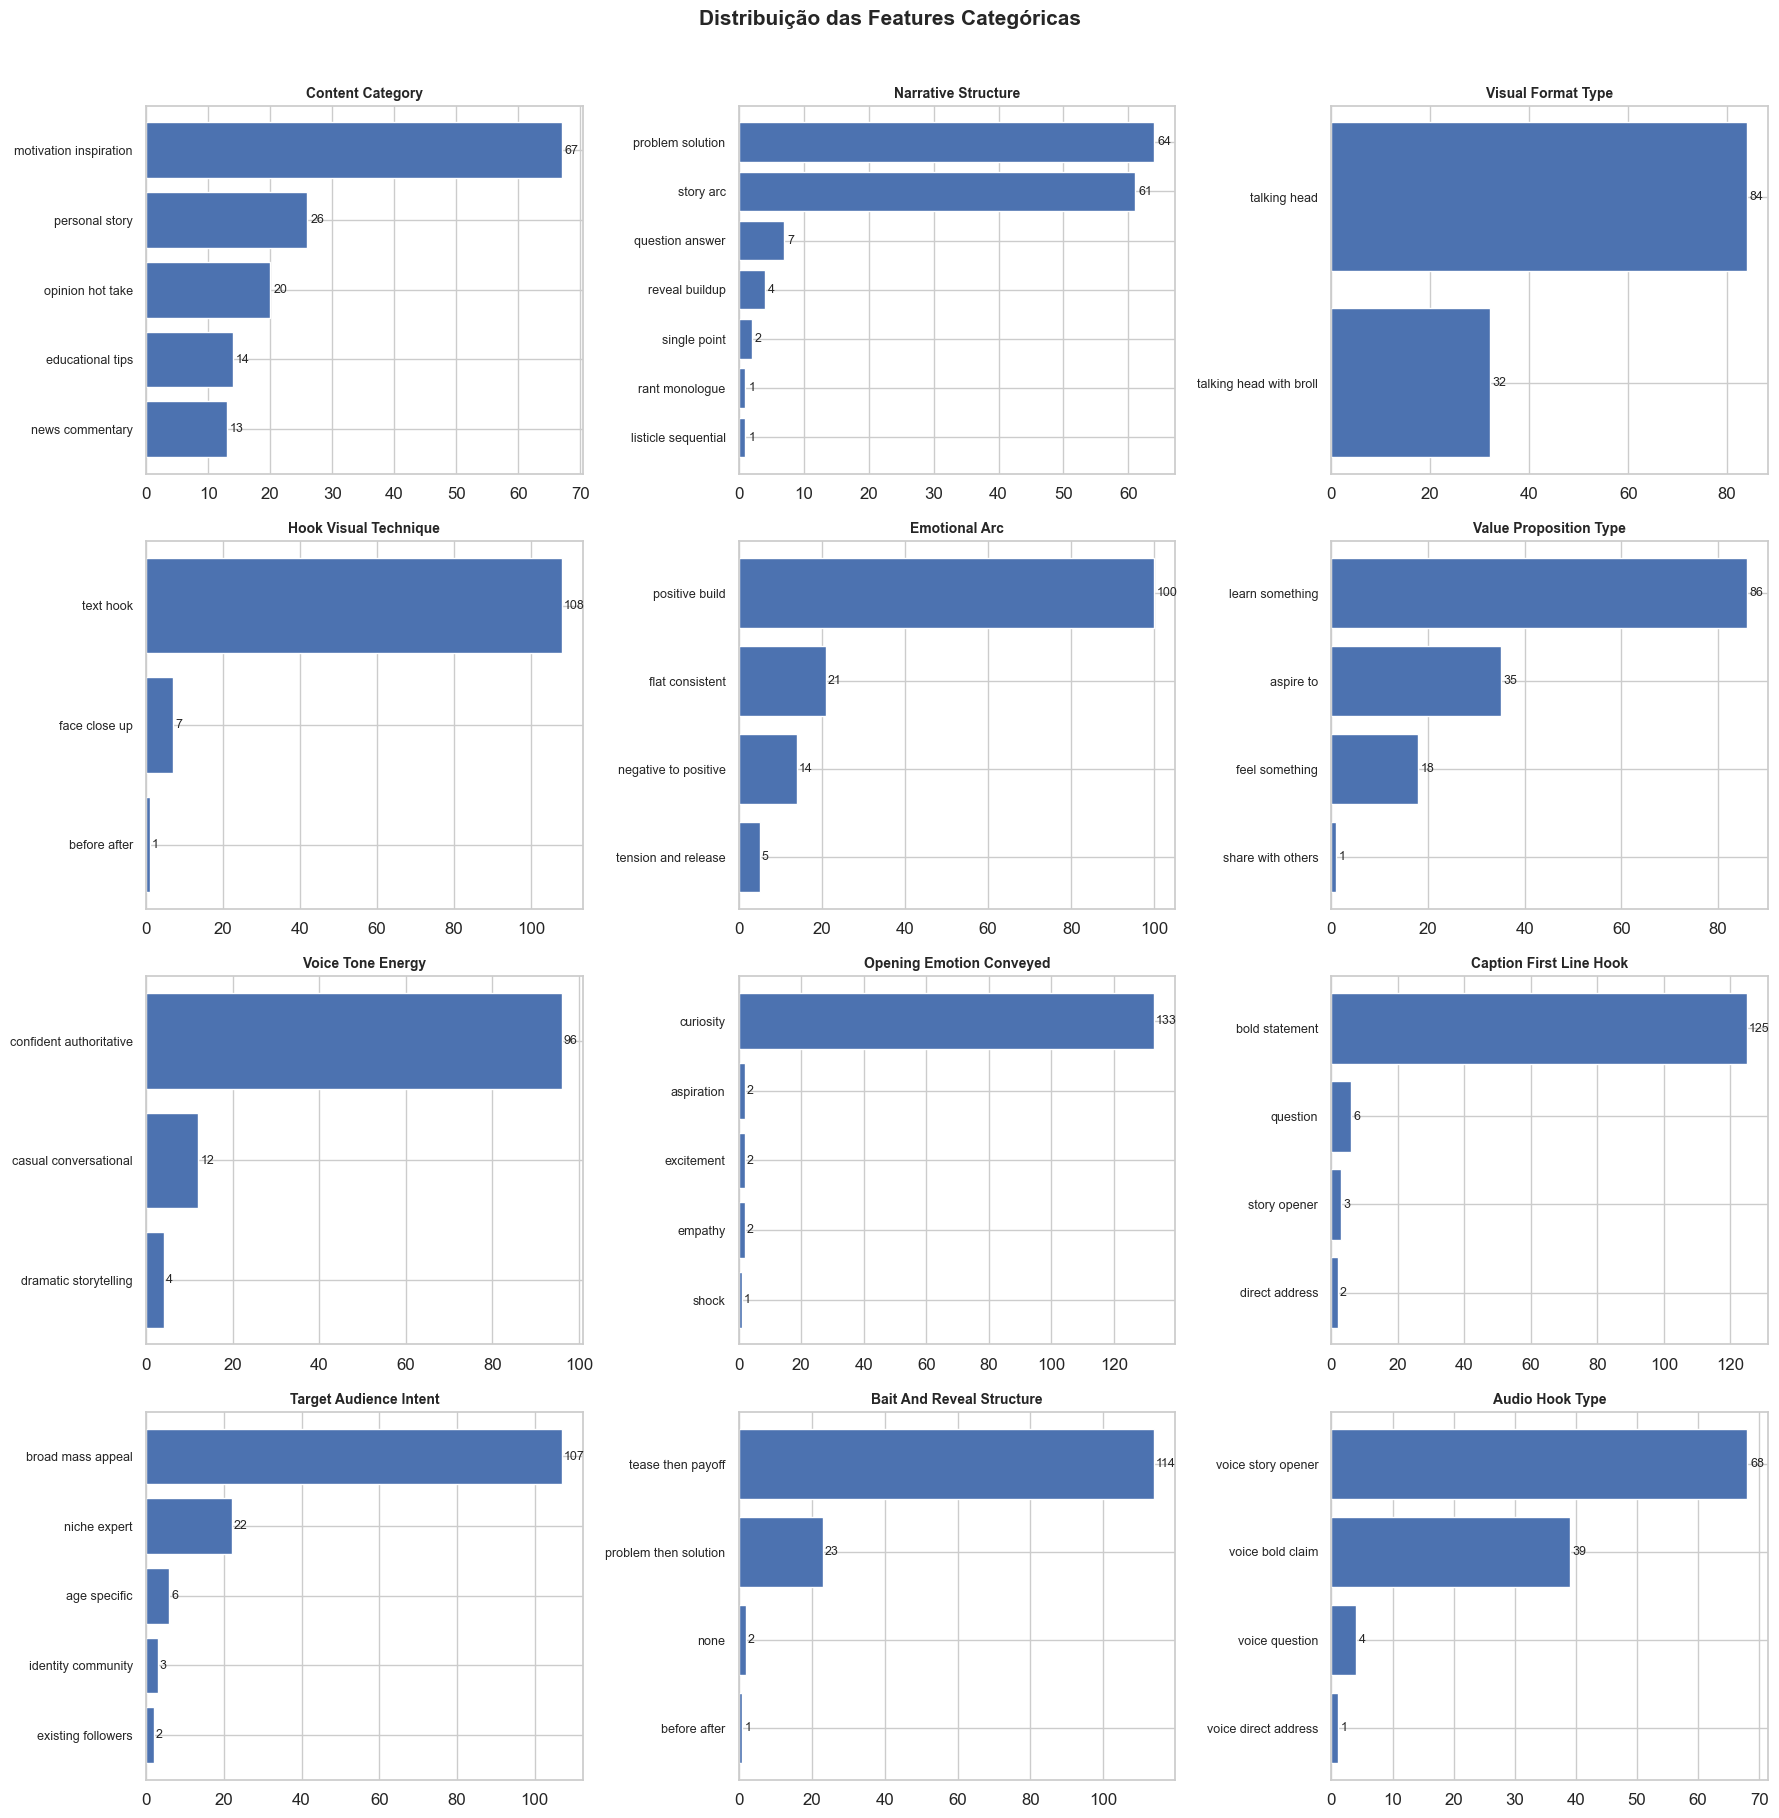

In [8]:
cat_features = [
    "content_category", "narrative_structure", "visual_format_type",
    "hook_visual_technique", "emotional_arc", "value_proposition_type",
    "voice_tone_energy", "opening_emotion_conveyed",
    "caption_first_line_hook", "target_audience_intent",
    "bait_and_reveal_structure", "audio_hook_type",
]

fig, axes = plt.subplots(4, 3, figsize=(18, 18))
for ax, feat in zip(axes.flat, cat_features):
    counts = df[feat].dropna().value_counts()
    bars = ax.barh(range(len(counts)), counts.values, color="#4C72B0", edgecolor="white")
    ax.set_yticks(range(len(counts)))
    ax.set_yticklabels([v.replace("_", " ") for v in counts.index], fontsize=9)
    ax.set_title(feat.replace("_", " ").title(), fontsize=10, fontweight="bold")
    ax.invert_yaxis()
    for bar, val in zip(bars, counts.values):
        ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                str(val), va="center", fontsize=9)

fig.suptitle("Distribuição das Features Categóricas", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

## 6. Correlação Spearman: Todas as Features × Métricas

### 6a. Reels (116 posts)

=== 6a. REELS (116 posts) ===


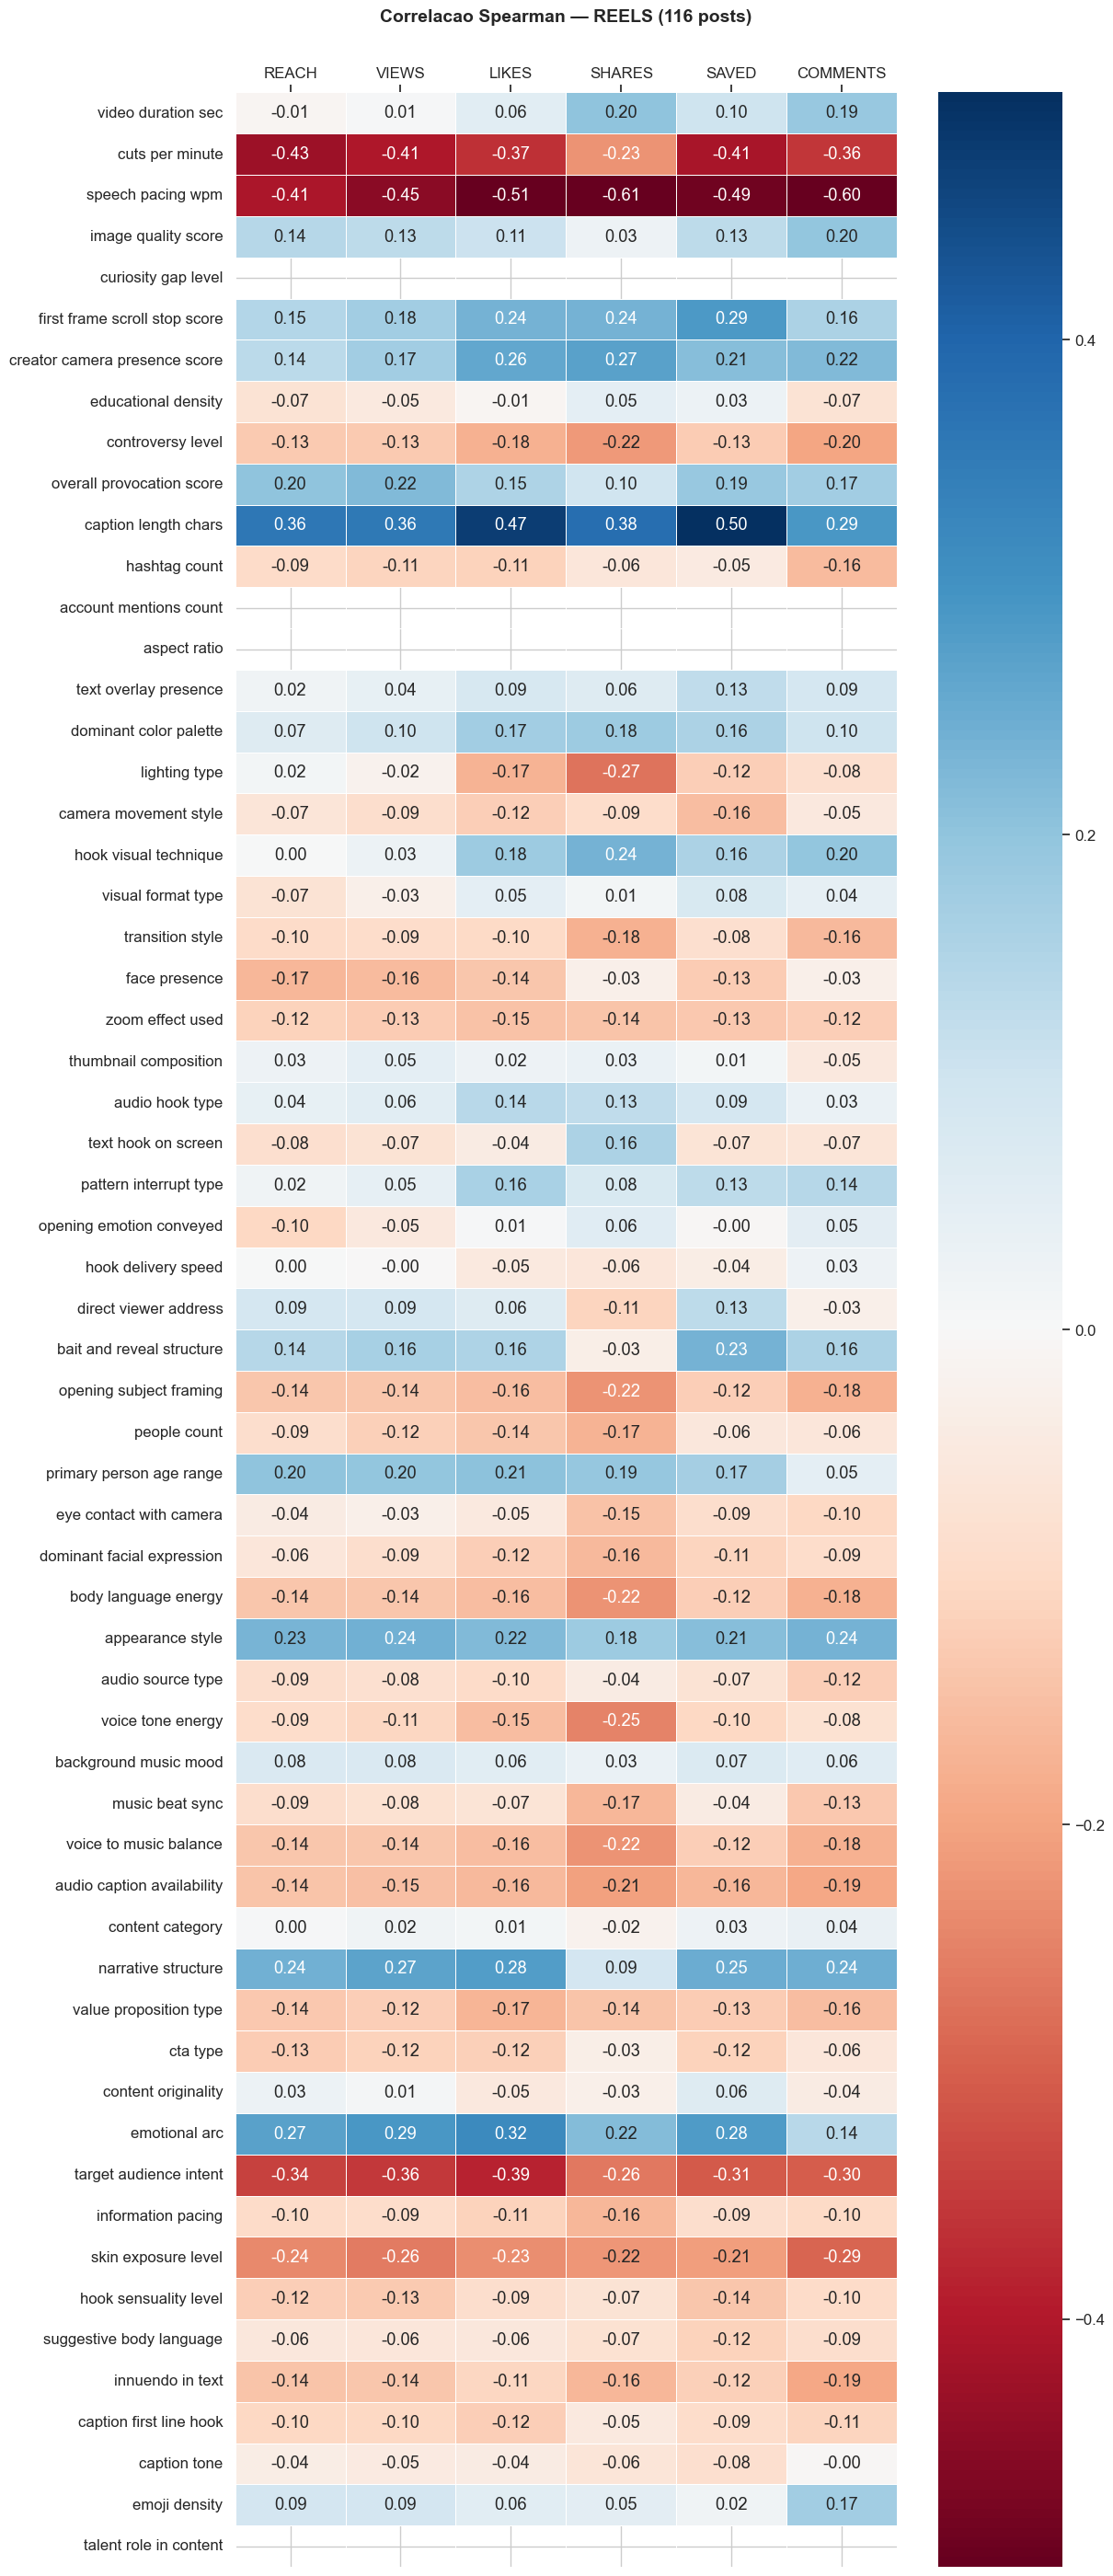

  60 features (13 numericas + 47 categoricas)


In [9]:
from sklearn.preprocessing import OrdinalEncoder

num_features = [
    "video_duration_sec", "cuts_per_minute", "speech_pacing_wpm",
    "image_quality_score", "curiosity_gap_level", "first_frame_scroll_stop_score",
    "creator_camera_presence_score", "educational_density",
    "controversy_level", "overall_provocation_score",
    "caption_length_chars", "hashtag_count", "account_mentions_count",
]

cat_features = [
    "aspect_ratio", "text_overlay_presence", "dominant_color_palette",
    "lighting_type", "camera_movement_style", "hook_visual_technique",
    "visual_format_type", "transition_style", "face_presence",
    "zoom_effect_used", "thumbnail_composition",
    "audio_hook_type", "text_hook_on_screen", "pattern_interrupt_type",
    "opening_emotion_conveyed", "hook_delivery_speed",
    "direct_viewer_address", "bait_and_reveal_structure",
    "opening_subject_framing", "people_count", "primary_person_age_range",
    "eye_contact_with_camera", "dominant_facial_expression",
    "body_language_energy", "appearance_style",
    "audio_source_type", "voice_tone_energy", "background_music_mood",
    "music_beat_sync", "voice_to_music_balance", "audio_caption_availability",
    "content_category", "narrative_structure", "value_proposition_type",
    "cta_type", "content_originality", "emotional_arc",
    "target_audience_intent", "information_pacing",
    "skin_exposure_level", "hook_sensuality_level", "suggestive_body_language",
    "innuendo_in_text", "caption_first_line_hook", "caption_tone", "emoji_density",
    "talent_role_in_content",
]

corr_metrics = ["reach", "views", "likes", "shares", "saved", "comments"]


def compute_spearman_heatmap(data, num_feats, cat_feats, metrics, title, min_non_null=20):
    avail_cat = [f for f in cat_feats if f in data.columns and data[f].notna().sum() >= min_non_null]
    avail_num = [f for f in num_feats if f in data.columns and data[f].notna().sum() >= min_non_null]
    avail = avail_num + avail_cat

    X = data[avail].copy()
    enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    X[avail_cat] = enc.fit_transform(X[avail_cat].fillna("__MISSING__"))
    X[avail_num] = X[avail_num].fillna(X[avail_num].median())

    sp = pd.DataFrame(index=avail, columns=metrics, dtype=float)
    for metric in metrics:
        y = data[metric].values
        for feat in avail:
            x = X[feat].values
            valid = ~(np.isnan(x) | np.isnan(y))
            if valid.sum() > 10:
                rho, _ = stats.spearmanr(x[valid], y[valid])
                sp.loc[feat, metric] = rho
    sp = sp.astype(float)

    height = max(10, len(avail) * 0.47)
    fig, ax = plt.subplots(figsize=(12, height))
    sns.heatmap(sp, annot=True, fmt=".2f", cmap="RdBu", center=0,
                vmin=-0.5, vmax=0.5, linewidths=0.5, ax=ax,
                yticklabels=[f.replace("_", " ") for f in avail],
                xticklabels=[m.upper() for m in metrics])
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")
    ax.set_title(f"{title}\n", fontweight="bold", fontsize=14, pad=20)
    plt.tight_layout()
    plt.show()

    print(f"  {len(avail)} features ({len(avail_num)} numericas + {len(avail_cat)} categoricas)")
    return sp


print("=== 6a. REELS (116 posts) ===")
sp_reels = compute_spearman_heatmap(
    reels, num_features, cat_features, corr_metrics,
    "Correlacao Spearman — REELS (116 posts)"
)

### 6b. Carrosséis (24 posts)

Nota: amostra menor (24 posts) — correlações menos estáveis. Features exclusivas de Reels são automaticamente excluídas.

=== 6b. CARROSSEIS (24 posts) ===


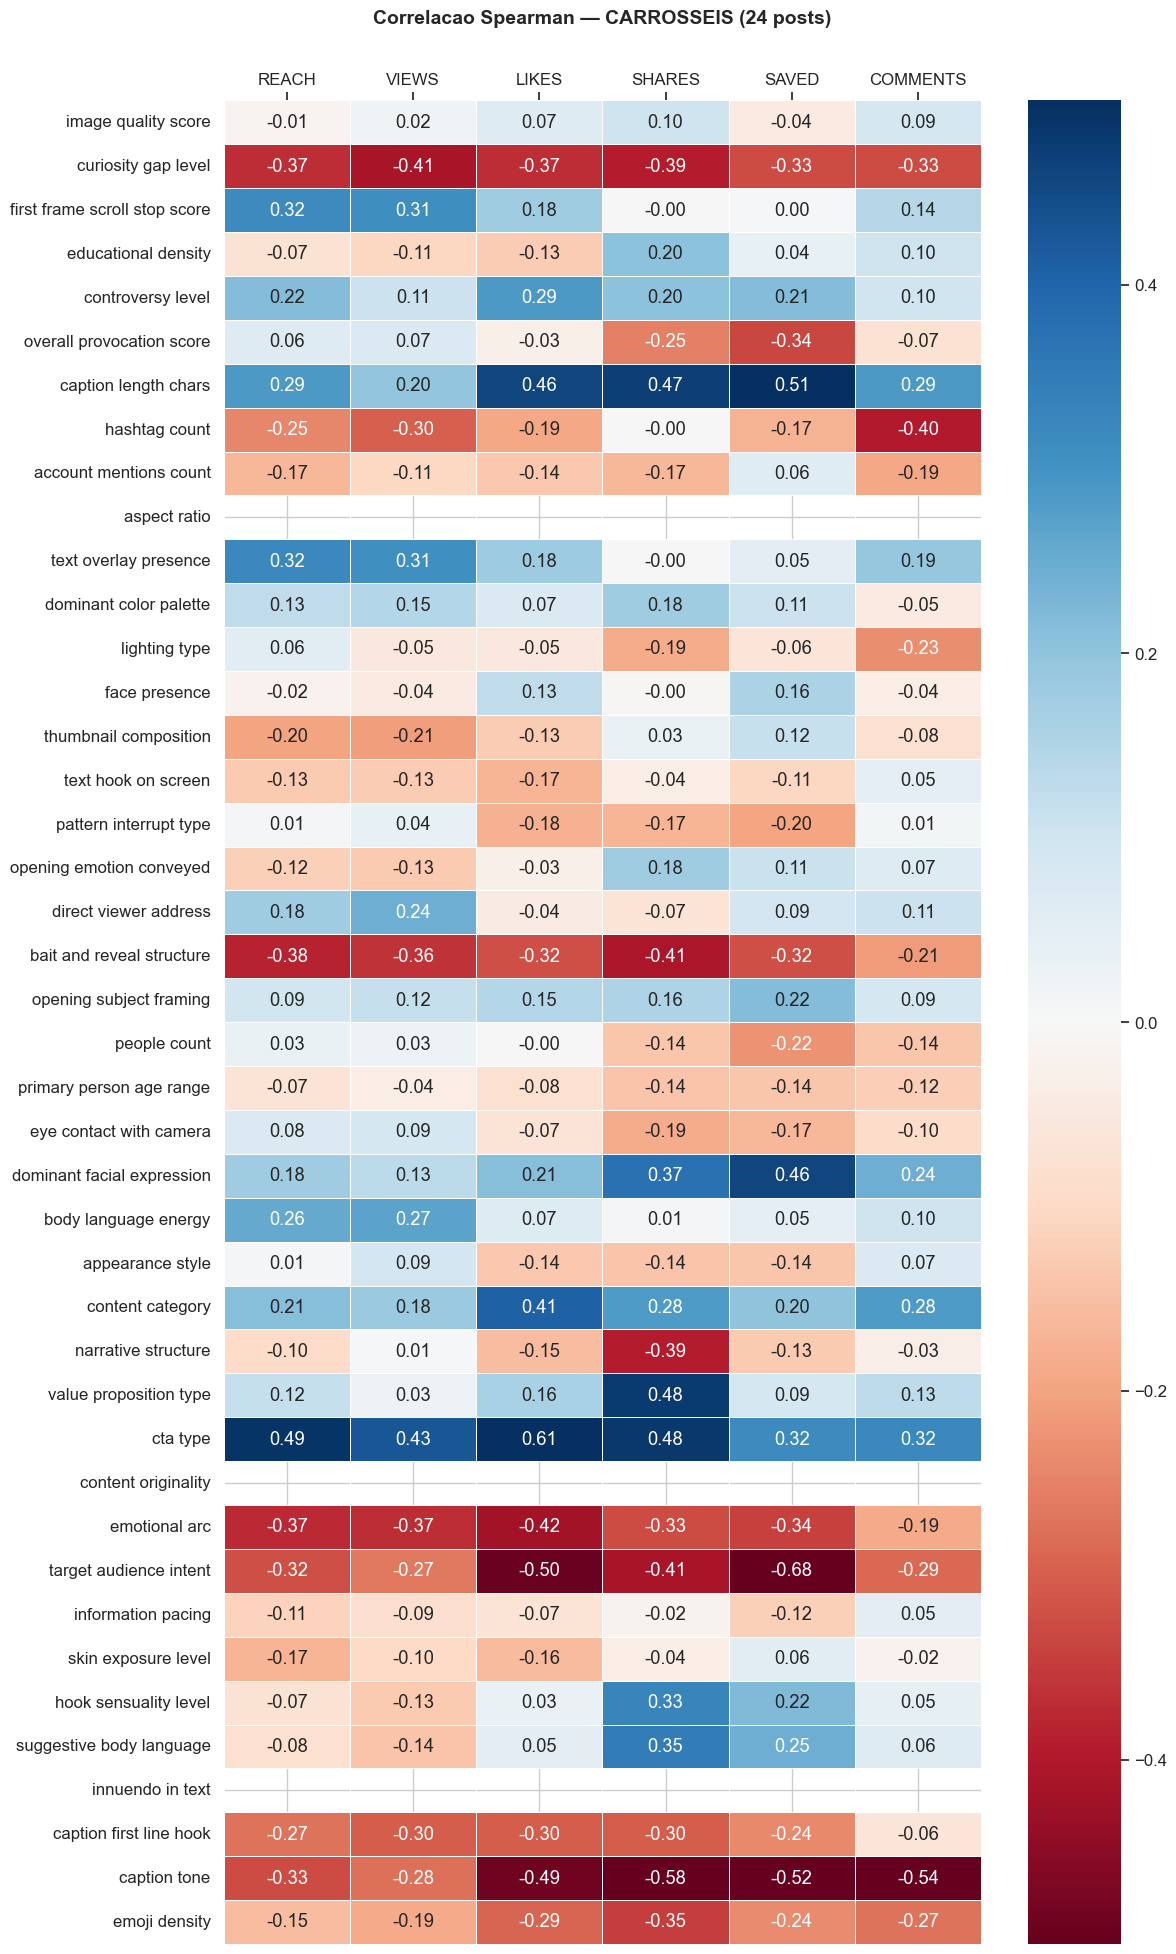

  42 features (9 numericas + 33 categoricas)


In [10]:
print("=== 6b. CARROSSEIS (24 posts) ===")
sp_carousels = compute_spearman_heatmap(
    carousels, num_features, cat_features, corr_metrics,
    "Correlacao Spearman — CARROSSEIS (24 posts)",
    min_non_null=10,
)

## 7. Correlações: Features Categóricas vs Reach (mediana por grupo)

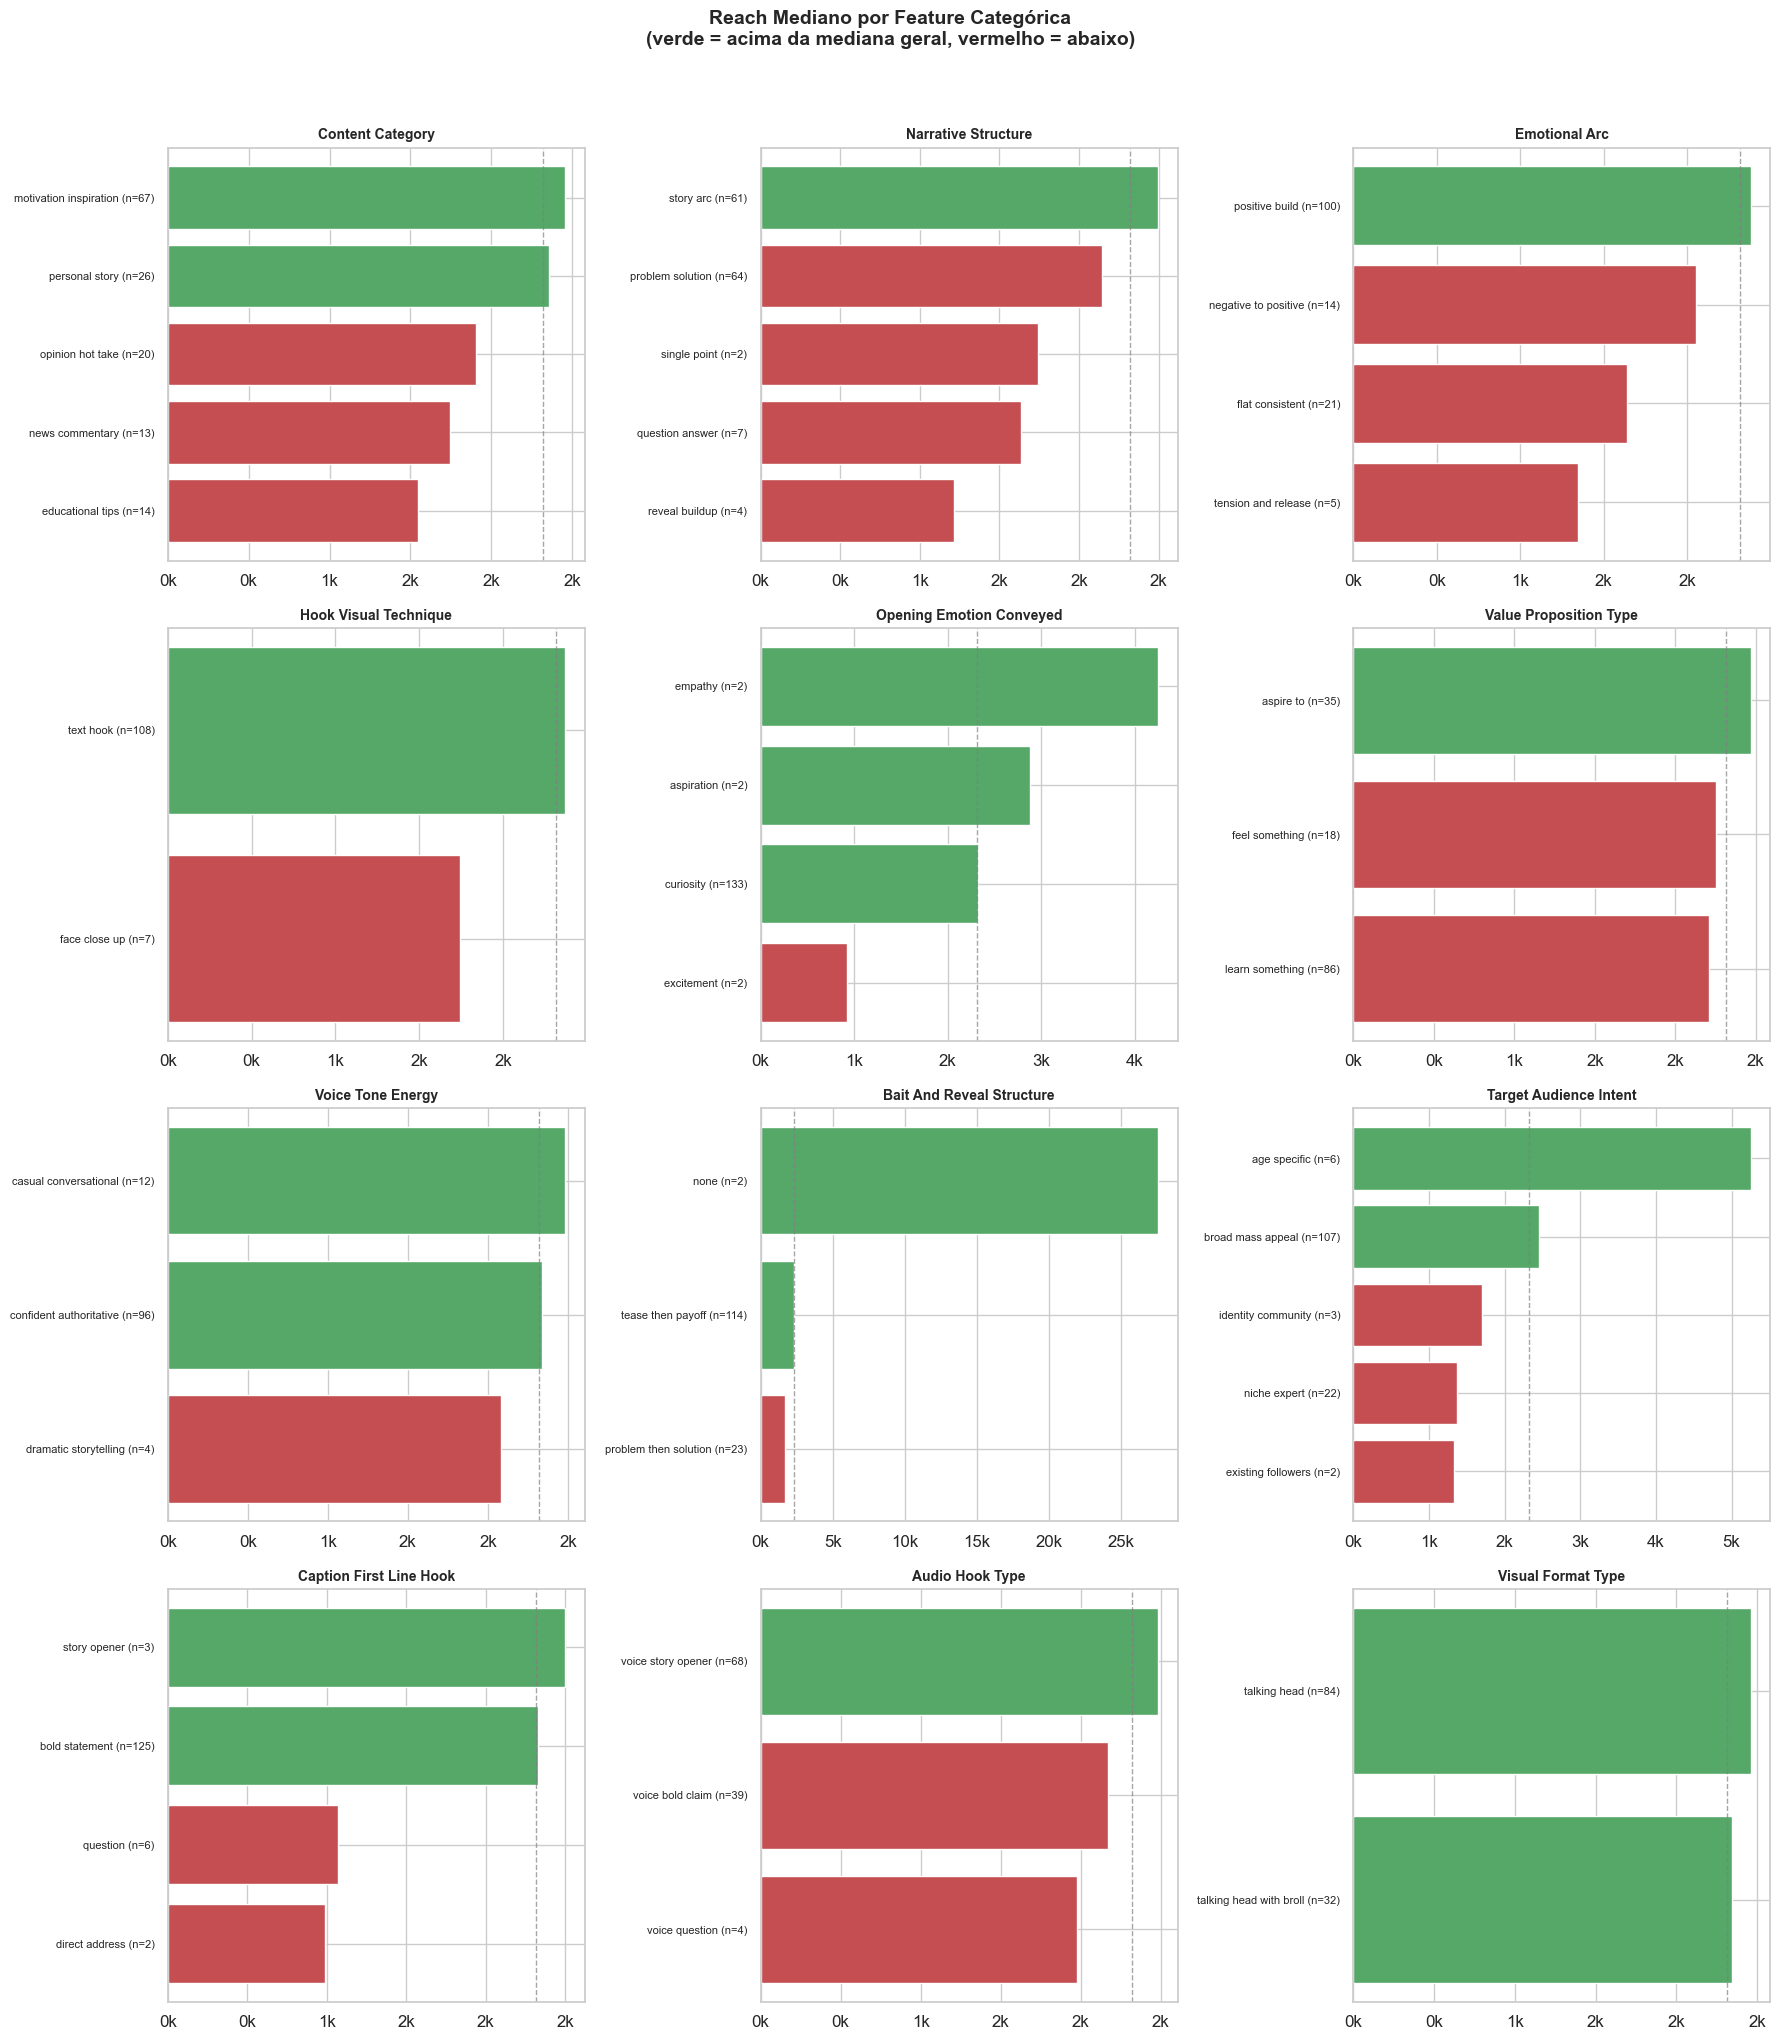

In [11]:
cat_for_reach = [
    "content_category", "narrative_structure", "emotional_arc",
    "hook_visual_technique", "opening_emotion_conveyed", "value_proposition_type",
    "voice_tone_energy", "bait_and_reveal_structure",
    "target_audience_intent", "caption_first_line_hook",
    "audio_hook_type", "visual_format_type",
]

fig, axes = plt.subplots(4, 3, figsize=(18, 20))
overall_median = df["reach"].median()

for ax, feat in zip(axes.flat, cat_for_reach):
    grouped = df.groupby(feat)["reach"].agg(["median", "count"]).sort_values("median", ascending=True)
    grouped = grouped[grouped["count"] >= 2]
    colors = ["#C44E52" if m < overall_median else "#55A868" for m in grouped["median"]]
    bars = ax.barh(range(len(grouped)), grouped["median"], color=colors, edgecolor="white")
    ax.axvline(overall_median, color="gray", ls="--", lw=1, alpha=0.7)
    ax.set_yticks(range(len(grouped)))
    labels = [f'{v.replace("_", " ")} (n={int(grouped.loc[v, "count"])})' for v in grouped.index]
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_title(feat.replace("_", " ").title(), fontsize=10, fontweight="bold")
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))

fig.suptitle("Reach Mediano por Feature Categórica\n(verde = acima da mediana geral, vermelho = abaixo)",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 8. Top & Bottom Performers — O que diferencia posts virais?

Top 25% (reach >= 3,063): 29 Reels
Bottom 25% (reach <= 1,674): 29 Reels


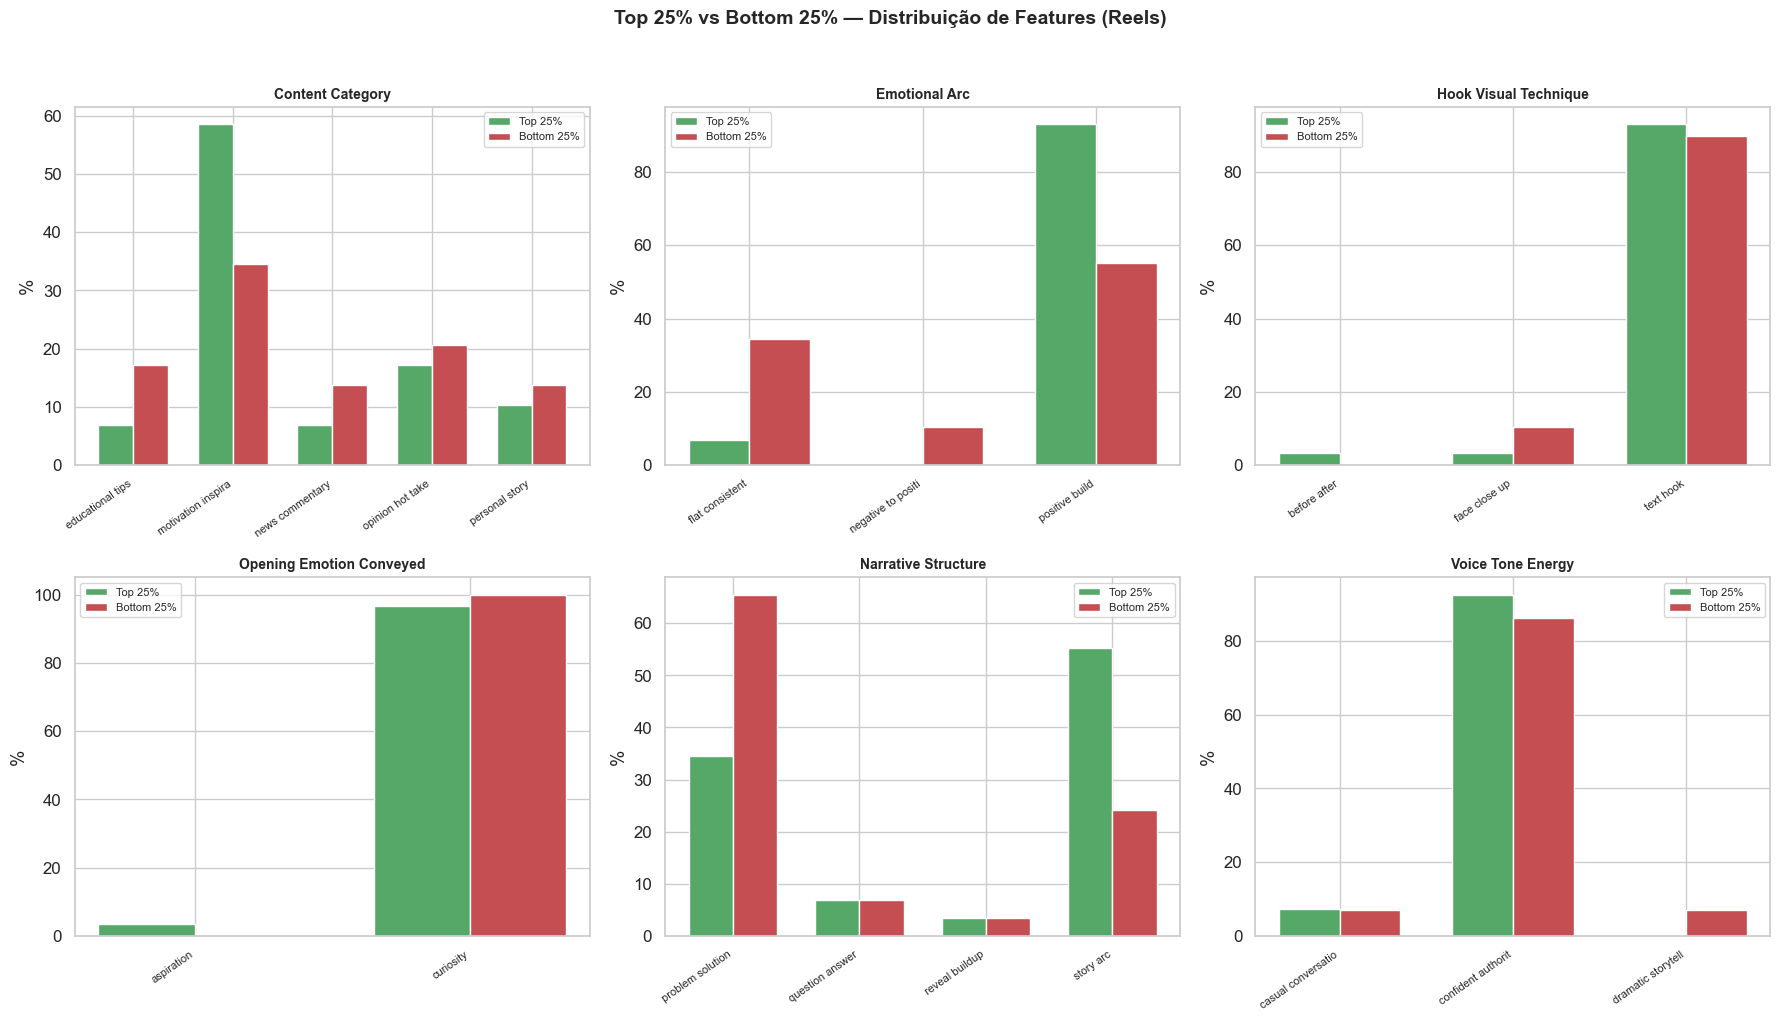

In [12]:
q75 = reels["reach"].quantile(0.75)
q25 = reels["reach"].quantile(0.25)

top = reels[reels["reach"] >= q75].copy()
bottom = reels[reels["reach"] <= q25].copy()

print(f"Top 25% (reach >= {q75:,.0f}): {len(top)} Reels")
print(f"Bottom 25% (reach <= {q25:,.0f}): {len(bottom)} Reels")

compare_cats = [
    "content_category", "emotional_arc", "hook_visual_technique",
    "opening_emotion_conveyed", "narrative_structure", "voice_tone_energy",
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, feat in zip(axes.flat, compare_cats):
    top_pct = top[feat].dropna().value_counts(normalize=True) * 100
    bot_pct = bottom[feat].dropna().value_counts(normalize=True) * 100
    all_vals = sorted(set(top_pct.index) | set(bot_pct.index))

    x = range(len(all_vals))
    w = 0.35
    ax.bar([i - w/2 for i in x], [top_pct.get(v, 0) for v in all_vals], w,
           label="Top 25%", color="#55A868", edgecolor="white")
    ax.bar([i + w/2 for i in x], [bot_pct.get(v, 0) for v in all_vals], w,
           label="Bottom 25%", color="#C44E52", edgecolor="white")
    ax.set_xticks(list(x))
    ax.set_xticklabels([v.replace("_", " ")[:18] for v in all_vals], rotation=35, ha="right", fontsize=8)
    ax.set_ylabel("%")
    ax.set_title(feat.replace("_", " ").title(), fontsize=10, fontweight="bold")
    ax.legend(fontsize=8)

fig.suptitle("Top 25% vs Bottom 25% — Distribuição de Features (Reels)",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

In [13]:
compare_nums = [
    "video_duration_sec", "cuts_per_minute", "speech_pacing_wpm",
    "curiosity_gap_level", "first_frame_scroll_stop_score",
    "creator_camera_presence_score", "caption_length_chars",
]

print("Feature numéricas — Top 25% vs Bottom 25% (Reels):\n")
print(f"{'Feature':>38s}  {'Top 25%':>10s}  {'Bottom 25%':>10s}  {'Diff':>8s}")
print("-" * 72)
for feat in compare_nums:
    t = top[feat].dropna().median()
    b = bottom[feat].dropna().median()
    diff = t - b
    sign = "+" if diff > 0 else ""
    print(f"{feat:>38s}  {t:>10.1f}  {b:>10.1f}  {sign}{diff:>7.1f}")

Feature numéricas — Top 25% vs Bottom 25% (Reels):

                               Feature     Top 25%  Bottom 25%      Diff
------------------------------------------------------------------------
                    video_duration_sec        81.0        81.0      0.0
                       cuts_per_minute         8.4        12.6     -4.2
                     speech_pacing_wpm       169.0       196.0    -27.0
                   curiosity_gap_level         3.0         3.0      0.0
         first_frame_scroll_stop_score         7.0         7.0      0.0
         creator_camera_presence_score         7.0         7.0      0.0
                  caption_length_chars      1492.0      1218.0  +  274.0


## 9. Heatmap de Correlação entre Métricas

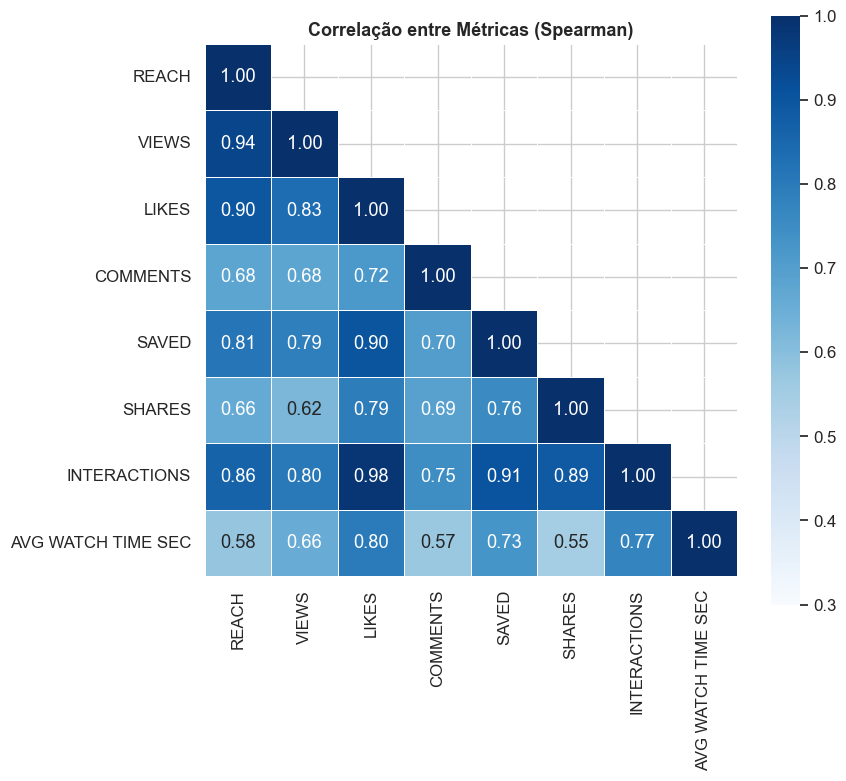

In [14]:
metric_cols = ["reach", "views", "likes", "comments", "saved", "shares",
               "interactions", "avg_watch_time_sec"]
corr = df[metric_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", mask=mask,
            square=True, linewidths=0.5, ax=ax, vmin=0.3, vmax=1.0,
            xticklabels=[c.replace("_", " ").upper() for c in metric_cols],
            yticklabels=[c.replace("_", " ").upper() for c in metric_cols])
ax.set_title("Correlação entre Métricas (Spearman)", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

## 10. Scatter Plots: Features mais interessantes vs Reach

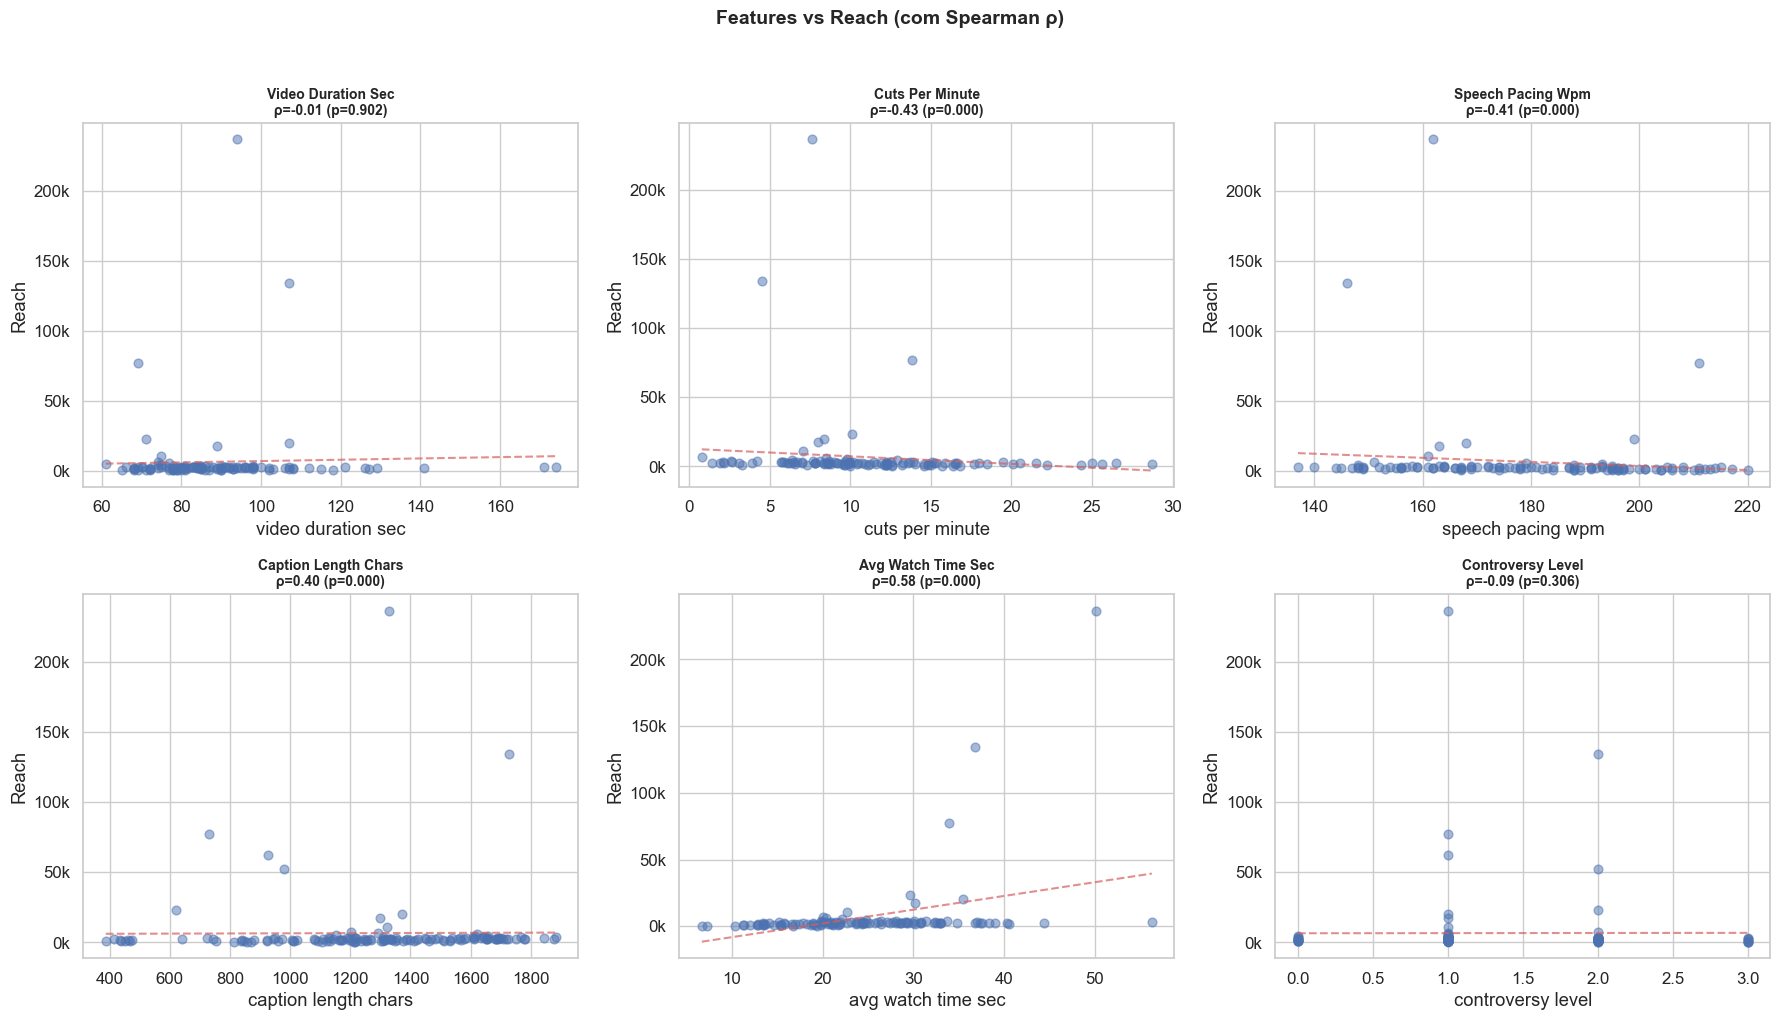

In [15]:
scatter_features = [
    "video_duration_sec", "cuts_per_minute", "speech_pacing_wpm",
    "caption_length_chars", "avg_watch_time_sec", "controversy_level",
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, feat in zip(axes.flat, scatter_features):
    mask = df[feat].notna() & df["reach"].notna()
    x = df.loc[mask, feat]
    y = df.loc[mask, "reach"]
    ax.scatter(x, y, alpha=0.5, s=40, c="#4C72B0")
    if len(x) > 5:
        rho, pval = stats.spearmanr(x, y)
        z = np.polyfit(x, y, 1)
        ax.plot(np.sort(x), np.polyval(z, np.sort(x)), "r--", lw=1.5, alpha=0.7)
        ax.set_xlabel(feat.replace("_", " "))
        ax.set_title(f"{feat.replace('_', ' ').title()}\nρ={rho:.2f} (p={pval:.3f})",
                      fontsize=10, fontweight="bold")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
    ax.set_ylabel("Reach")

fig.suptitle("Features vs Reach (com Spearman ρ)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 11. Reels: Watch Time vs Reach (engajamento de retenção)

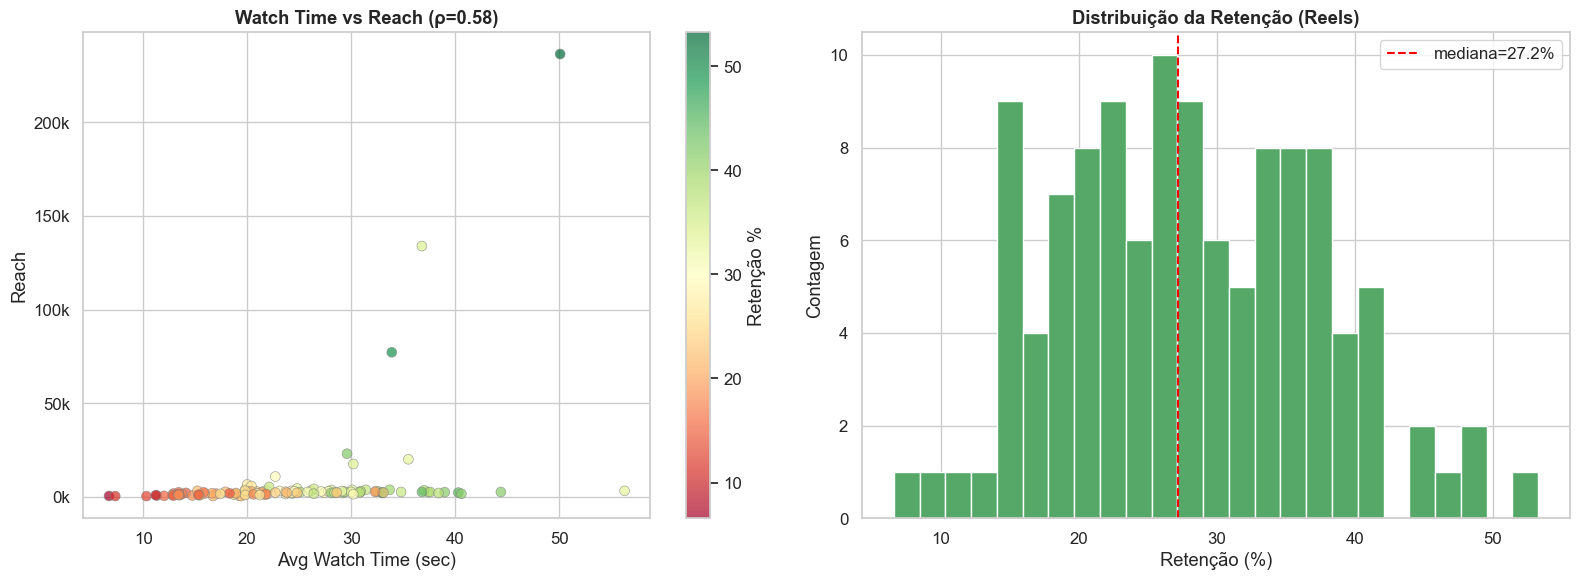

Retenção média: 27.9%
Retenção mediana: 27.2%


In [16]:
r = reels.dropna(subset=["avg_watch_time_sec", "video_duration_sec"]).copy()
r["retention_pct"] = (r["avg_watch_time_sec"] / r["video_duration_sec"] * 100).clip(upper=100)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
sc = ax.scatter(r["avg_watch_time_sec"], r["reach"], c=r["retention_pct"],
                cmap="RdYlGn", s=50, alpha=0.7, edgecolors="gray", lw=0.5)
plt.colorbar(sc, ax=ax, label="Retenção %")
rho, _ = stats.spearmanr(r["avg_watch_time_sec"], r["reach"])
ax.set_xlabel("Avg Watch Time (sec)")
ax.set_ylabel("Reach")
ax.set_title(f"Watch Time vs Reach (ρ={rho:.2f})", fontweight="bold")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))

ax = axes[1]
ax.hist(r["retention_pct"], bins=25, edgecolor="white", color="#55A868")
ax.axvline(r["retention_pct"].median(), color="red", ls="--", lw=1.5,
           label=f'mediana={r["retention_pct"].median():.1f}%')
ax.set_xlabel("Retenção (%)")
ax.set_ylabel("Contagem")
ax.set_title("Distribuição da Retenção (Reels)", fontweight="bold")
ax.legend()

plt.tight_layout()
plt.show()

print(f"Retenção média: {r['retention_pct'].mean():.1f}%")
print(f"Retenção mediana: {r['retention_pct'].median():.1f}%")

## 12. Resumo dos Achados

In [17]:
print("=" * 60)
print("RESUMO DA EDA — ACHADOS PRINCIPAIS")
print("=" * 60)

print(f"""
1. VOLUME E TIPOS
   - {len(reels)} Reels + {len(carousels)} Carrosséis no período
   - Frequência: ~{len(df) / ((df['date_br'].max() - df['date_br'].min()).days / 7):.1f} posts/semana

2. PERFORMANCE GERAL (Reels)
   - Reach mediano: {reels['reach'].median():,.0f}
   - Views mediano: {reels['views'].median():,.0f}
   - Likes mediano: {reels['likes'].median():,.0f}
   - Shares mediano: {reels['shares'].median():,.0f}
   - Watch time médio: {reels['avg_watch_time_sec'].median():.1f}s

3. REELS vs CARROSSÉIS
   - Reels dominam em reach ({reels['reach'].median():,.0f} vs {carousels['reach'].median():,.0f})
   - Reels dominam em shares ({reels['shares'].median():,.0f} vs {carousels['shares'].median():,.0f})

4. PERFIL DO CONTEÚDO
   - Duração típica: {reels['video_duration_sec'].median():.0f}s
   - Cortes/minuto: {reels['cuts_per_minute'].median():.1f}
   - Pacing de fala: {reels['speech_pacing_wpm'].median():.0f} wpm
   - Caption médio: {df['caption_length_chars'].median():.0f} chars

5. VARIÂNCIA
   - Distribuição de reach é muito assimétrica (poucos virais, muitos médios)
   - Skewness do reach: {df['reach'].skew():.2f}
   - Top 10% do reach = {df['reach'].quantile(0.9):,.0f}+ (vs mediana {df['reach'].median():,.0f})
""")

RESUMO DA EDA — ACHADOS PRINCIPAIS

1. VOLUME E TIPOS
   - 116 Reels + 24 Carrosséis no período
   - Frequência: ~11.4 posts/semana

2. PERFORMANCE GERAL (Reels)
   - Reach mediano: 2,368
   - Views mediano: 2,924
   - Likes mediano: 128
   - Shares mediano: 36
   - Watch time médio: 23.7s

3. REELS vs CARROSSÉIS
   - Reels dominam em reach (2,368 vs 1,323)
   - Reels dominam em shares (36 vs 8)

4. PERFIL DO CONTEÚDO
   - Duração típica: 85s
   - Cortes/minuto: 10.1
   - Pacing de fala: 179 wpm
   - Caption médio: 1310 chars

5. VARIÂNCIA
   - Distribuição de reach é muito assimétrica (poucos virais, muitos médios)
   - Skewness do reach: 7.48
   - Top 10% do reach = 4,329+ (vs mediana 2,318)

